# RQ1 - Nelson-Siegel: uoc luong cau truc ky han

Muc tieu: trich xuat Level/Slope/Curvature tu loi suat da ky han, danh gia do phu hop (RMSE/R2), doi chieu OLS vs NLS.

In [1]:
import sys
sys.path.append('..')

from src import config, data_fetch, nelson_siegel as ns
import pandas as pd
import matplotlib.pyplot as plt

## 1. Lay du lieu

In [2]:
yields, macro, recession = data_fetch.fetch_fred_data()
maturities = list(config.TREASURY_SERIES.values())
yields.tail()

,DGS1MO,DGS3MO,DGS6MO,DGS1,DGS2,DGS3,DGS5,DGS7,DGS10,DGS20,DGS30
date,,,,,,,,,,,
2026-09-21,3.96,4.17,4.27,4.45,4.76,4.82,4.83,4.89,4.96,5.33,5.29
2026-09-22,3.97,4.16,4.26,4.43,4.71,4.81,4.83,4.89,4.96,5.33,5.29
2026-09-23,3.99,4.19,4.31,4.49,4.85,4.97,4.99,5.05,5.11,5.45,5.40
2026-09-24,4.01,4.24,4.34,4.51,4.87,4.99,5.03,5.10,5.18,5.53,5.47
2026-09-25,4.04,4.24,4.33,4.50,4.81,4.94,4.98,5.06,5.17,5.54,5.49


## 2. Uoc luong NS (OLS, lambda co dinh) cho toan bo chuoi

In [3]:
factors_ols = ns.estimate_ns_timeseries(yields, maturities, method='ols')
factors_ols[['level','slope','curvature','rmse','r2']].describe()

,level,slope,curvature,rmse,r2
count,6687.000000,6687.000000,6687.000000,6687.000000,6687.000000
mean,4.078880,-2.024189,-2.622494,0.102781,0.923813
std,1.245748,1.789897,2.260604,0.049767,0.139496
min,0.970341,-5.277673,-7.545850,0.018957,0.000411
25%,3.018708,-3.524810,-4.472373,0.069127,0.925764
50%,4.363236,-2.186098,-2.440053,0.092770,0.977169
75%,5.006262,-0.530550,-1.147156,0.125011,0.994154
max,6.826324,2.202701,4.147285,0.487043,0.999880


## 3. Doi chieu OLS vs NLS tren mot mau (vd 252 ngay gan nhat)

In [4]:
comparison, nls_conv_rate = ns.compare_ols_vs_nls(yields, maturities, sample_size=252)
print(f'NLS convergence rate: {nls_conv_rate:.1%}')
comparison.head()

NLS convergence rate: 100.0%


,level_ols,slope_ols,curvature_ols,lam_ols,rmse_ols,r2_ols,converged_ols,n_maturities_ols,level_nls,slope_nls,curvature_nls,lam_nls,rmse_nls,r2_nls,converged_nls,n_maturities_nls
date,,,,,,,,,,,,,,,,
2025-09-24,4.887437,-0.593725,-3.815015,0.7308,0.093473,0.946025,True,11,5.111794,-0.940207,-3.718107,0.500193,0.053797,0.982121,True,11
2025-09-25,4.873369,-0.553742,-3.625172,0.7308,0.093138,0.940509,True,11,5.084155,-0.880342,-3.533792,0.501563,0.060499,0.974899,True,11
2025-09-26,4.896081,-0.599879,-3.634179,0.7308,0.089420,0.947001,True,11,5.095380,-0.910775,-3.525217,0.510279,0.058512,0.977307,True,11
2025-09-29,4.834673,-0.529240,-3.590085,0.7308,0.088788,0.943844,True,11,5.029198,-0.833324,-3.504890,0.512544,0.059508,0.974775,True,11
2025-09-30,4.857506,-0.561862,-3.644797,0.7308,0.087304,0.948082,True,11,5.063046,-0.880827,-3.553768,0.506843,0.051224,0.982127,True,11


## 4. Truc quan hoa fit tai vai thoi diem dac trung

Chon 3 ngay theo slope NS (β1), quy uoc Diebold–Li: y(∞)−y(0)=−β1.
- **normal**: β1 min (am sau) → doc len
- **flat**: |β1| **nho nhat** → thuong ~0 (dung la dang phang; -0.00 chi la lam tron 2 chu so)
- **inverted**: β1 max (duong lon) → dao nguoc


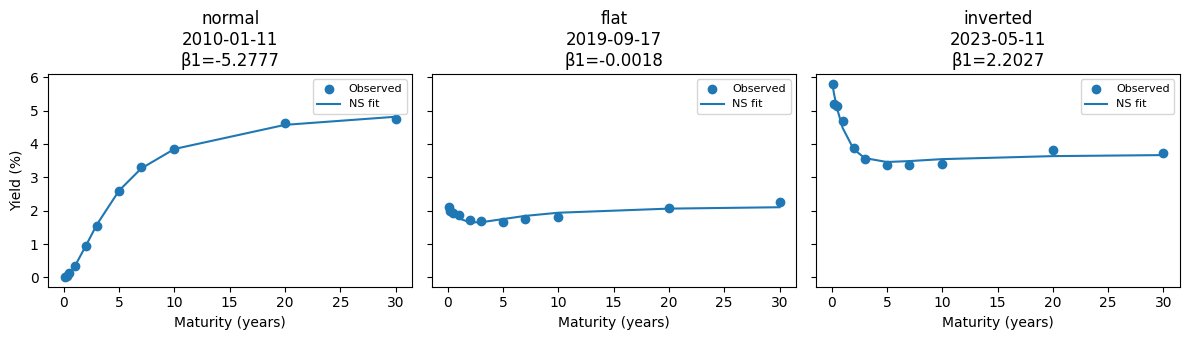

Dates: {'normal': '2010-01-11', 'flat': '2019-09-17', 'inverted': '2023-05-11'}
beta1 (raw): {'normal': -5.277672597715464, 'flat': -0.0018363768524094493, 'inverted': 2.2027005133822617}


In [5]:
import numpy as np
from pathlib import Path

codes = list(config.TREASURY_SERIES.keys())
slope = factors_ols['slope']
# Diebold-Li: y(inf)-y(0) = -beta1
# flat = |beta1| nho nhat → thuong ~ 0 (dung la dang phang; -0.00 chi la lam tron)
dates = {
    'normal': slope.idxmin(),
    'flat': slope.abs().idxmin(),
    'inverted': slope.idxmax(),
}
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True)
for ax, (label, dt) in zip(axes, dates.items()):
    row = yields.loc[dt, codes]
    b0, b1, b2, lam = factors_ols.loc[dt, ['level', 'slope', 'curvature', 'lam']]
    tau = np.asarray(maturities, dtype=float)
    fitted = ns.nelson_siegel(tau, b0, b1, b2, lam)
    ax.scatter(tau, row.values, label='Observed', zorder=3)
    order = np.argsort(tau)
    ax.plot(tau[order], fitted[order], label='NS fit')
    ax.set_title(f"{label}\n{pd.Timestamp(dt).date()}\nβ1={b1:.4f}")
    ax.set_xlabel('Maturity (years)')
    ax.legend(fontsize=8)
axes[0].set_ylabel('Yield (%)')
fig.tight_layout()
Path('../outputs').mkdir(exist_ok=True)
fig.savefig('../outputs/rq1_ns_fit_shapes.png', dpi=150)
plt.show()
print('Dates:', {k: str(pd.Timestamp(v).date()) for k, v in dates.items()})
print('beta1 (raw):', {k: float(factors_ols.loc[v, 'slope']) for k, v in dates.items()})


## 5. Xuat ket qua cho cac buoc sau (RQ2, RQ3)

In [6]:
from pathlib import Path
from src.utils import ensure_monthly_freq, MONTHLY_FREQ

Path('../data').mkdir(exist_ok=True)
Path('../outputs').mkdir(exist_ok=True)
factors_monthly = ensure_monthly_freq(
    factors_ols[['level','slope','curvature']].resample(MONTHLY_FREQ).last()
)
factors_monthly.to_csv('../data/ns_factors_monthly.csv')
factors_ols.to_csv('../data/ns_factors_daily.csv')
factors_ols[['rmse','r2']].describe().to_csv('../outputs/rq1_fit_summary.csv')
factors_monthly.tail()

,level,slope,curvature
date,,,
2026-05,5.019246,-1.235283,-1.775704
2026-06,4.895557,-1.021234,-1.172478
2026-07,5.286283,-1.419788,-1.324546
2026-08,5.247621,-1.330492,-1.128791
2026-09,5.497331,-1.401444,-0.148833
